In [160]:
import pandas as pd
import pylab as pl
import numpy as np
import scipy.optimize as opt
from sklearn import preprocessing
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings("ignore")

In [161]:
# Carga de la base de datos
import os

cell_df = pd.read_csv("recursos_humanos (3).csv")
cell_df

,satisfaction_level,last_evaluation,number_project,average_montly_hours,time_spend_company,Work_accident,left,promotion_last_5years,sales,salary
0,0.38,0.53,2,157,3,0,1,0,sales,low
1,0.80,0.86,5,262,6,0,1,0,sales,medium
2,0.11,0.88,7,272,4,0,1,0,sales,medium
3,0.72,0.87,5,223,5,0,1,0,sales,low
4,0.37,0.52,2,159,3,0,1,0,sales,low
...,...,...,...,...,...,...,...,...,...,...
14994,0.40,0.57,2,151,3,0,1,0,support,low
14995,0.37,0.48,2,160,3,0,1,0,support,low
14996,0.37,0.53,2,143,3,0,1,0,support,low
14997,0.11,0.96,6,280,4,0,1,0,support,low


In [162]:
# Identificación de las clases
cell_df["left"].value_counts()

left
0    11428
1     3571
Name: count, dtype: int64

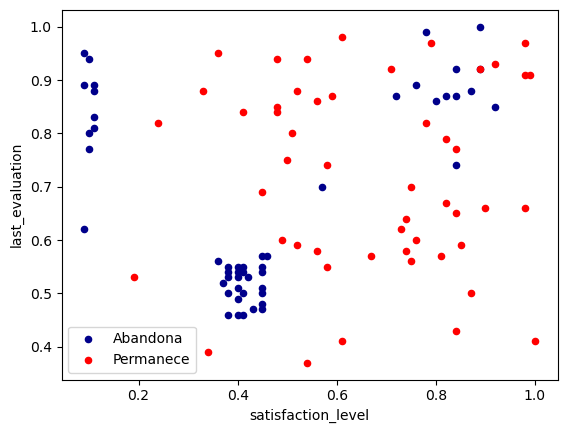

In [163]:
# Gráfica de empleados que permanecen y abandonan la empresa
ax = cell_df[cell_df["left"] == 1][0:50].plot(kind="scatter",x="satisfaction_level",y="last_evaluation",color="DarkBlue",label="Abandona")
ax = cell_df[cell_df["left"] == 0][0:50].plot(kind="scatter",x="satisfaction_level",y="last_evaluation",color="Red",label="Permanece",ax=ax)
plt.show()

In [164]:
# Preprocesamiento de datos y selección
cell_df.dtypes

satisfaction_level       float64
last_evaluation          float64
number_project             int64
average_montly_hours       int64
time_spend_company         int64
Work_accident              int64
left                       int64
promotion_last_5years      int64
sales                     object
salary                    object
dtype: object

In [165]:
# Revisión de valores faltantes
cell_df.isnull().sum()

satisfaction_level       0
last_evaluation          0
number_project           0
average_montly_hours     0
time_spend_company       0
Work_accident            0
left                     0
promotion_last_5years    0
sales                    0
salary                   0
dtype: int64

In [166]:
# Conversión de variables categóricas
cell_df = pd.get_dummies(cell_df,columns=["sales", "salary"],dtype=int)
cell_df

,satisfaction_level,last_evaluation,number_project,average_montly_hours,time_spend_company,Work_accident,left,promotion_last_5years,sales_IT,sales_RandD,...,sales_hr,sales_management,sales_marketing,sales_product_mng,sales_sales,sales_support,sales_technical,salary_high,salary_low,salary_medium
0,0.38,0.53,2,157,3,0,1,0,0,0,...,0,0,0,0,1,0,0,0,1,0
1,0.80,0.86,5,262,6,0,1,0,0,0,...,0,0,0,0,1,0,0,0,0,1
2,0.11,0.88,7,272,4,0,1,0,0,0,...,0,0,0,0,1,0,0,0,0,1
3,0.72,0.87,5,223,5,0,1,0,0,0,...,0,0,0,0,1,0,0,0,1,0
4,0.37,0.52,2,159,3,0,1,0,0,0,...,0,0,0,0,1,0,0,0,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
14994,0.40,0.57,2,151,3,0,1,0,0,0,...,0,0,0,0,0,1,0,0,1,0
14995,0.37,0.48,2,160,3,0,1,0,0,0,...,0,0,0,0,0,1,0,0,1,0
14996,0.37,0.53,2,143,3,0,1,0,0,0,...,0,0,0,0,0,1,0,0,1,0
14997,0.11,0.96,6,280,4,0,1,0,0,0,...,0,0,0,0,0,1,0,0,1,0


In [167]:
# Verificación de tipos de datos
cell_df.dtypes

satisfaction_level       float64
last_evaluation          float64
number_project             int64
average_montly_hours       int64
time_spend_company         int64
Work_accident              int64
left                       int64
promotion_last_5years      int64
sales_IT                   int64
sales_RandD                int64
sales_accounting           int64
sales_hr                   int64
sales_management           int64
sales_marketing            int64
sales_product_mng          int64
sales_sales                int64
sales_support              int64
sales_technical            int64
salary_high                int64
salary_low                 int64
salary_medium              int64
dtype: object

In [168]:
# Selección de variables independientes
feature_df = cell_df.drop(columns=["left"])
x = np.asarray(feature_df)
x[0:5]

array([[3.80e-01, 5.30e-01, 2.00e+00, 1.57e+02, 3.00e+00, 0.00e+00,
        0.00e+00, 0.00e+00, 0.00e+00, 0.00e+00, 0.00e+00, 0.00e+00,
        0.00e+00, 0.00e+00, 1.00e+00, 0.00e+00, 0.00e+00, 0.00e+00,
        1.00e+00, 0.00e+00],
       [8.00e-01, 8.60e-01, 5.00e+00, 2.62e+02, 6.00e+00, 0.00e+00,
        0.00e+00, 0.00e+00, 0.00e+00, 0.00e+00, 0.00e+00, 0.00e+00,
        0.00e+00, 0.00e+00, 1.00e+00, 0.00e+00, 0.00e+00, 0.00e+00,
        0.00e+00, 1.00e+00],
       [1.10e-01, 8.80e-01, 7.00e+00, 2.72e+02, 4.00e+00, 0.00e+00,
        0.00e+00, 0.00e+00, 0.00e+00, 0.00e+00, 0.00e+00, 0.00e+00,
        0.00e+00, 0.00e+00, 1.00e+00, 0.00e+00, 0.00e+00, 0.00e+00,
        0.00e+00, 1.00e+00],
       [7.20e-01, 8.70e-01, 5.00e+00, 2.23e+02, 5.00e+00, 0.00e+00,
        0.00e+00, 0.00e+00, 0.00e+00, 0.00e+00, 0.00e+00, 0.00e+00,
        0.00e+00, 0.00e+00, 1.00e+00, 0.00e+00, 0.00e+00, 0.00e+00,
        1.00e+00, 0.00e+00],
       [3.70e-01, 5.20e-01, 2.00e+00, 1.59e+02, 3.00e+00, 0.00e+00,


In [169]:
# Selección de la variable dependiente
cell_df["left"] = cell_df["left"].astype("int")
y = np.asarray(cell_df["left"])
y[0:5]

array([1, 1, 1, 1, 1])

In [170]:
# Creación de grupos de entrenamiento y prueba
X_train, X_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=4, stratify=y)
print("Grupo de entrenamiento", X_train.shape, y_train.shape)
print("Grupo de prueba", X_test.shape, y_test.shape)

Grupo de entrenamiento (11999, 20) (11999,)
Grupo de prueba (3000, 20) (3000,)


In [171]:
# Estandarización de las variables
from sklearn.preprocessing import StandardScaler
escalador = StandardScaler()
X_train = escalador.fit_transform(X_train)
X_test = escalador.transform(X_test)

# Modelación con SVM

## Kernel RBF

In [172]:
# Modelación con SVM - Kernel RBF
from sklearn import svm

clf = svm.SVC(kernel="rbf")
clf.fit(X_train, y_train)

yhat = clf.predict(X_test)
yhat[0:5]


array([0, 1, 0, 0, 1])

In [173]:
# Creación de la matriz de confusión
from sklearn.metrics import confusion_matrix
cm = confusion_matrix(y_test, yhat)
cm

array([[2212,   74],
       [  65,  649]])

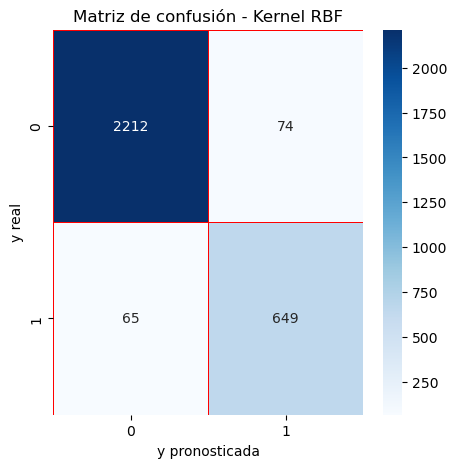

In [174]:
# Visualización de la matriz de confusión
f, ax = plt.subplots(figsize=(5,5))

sns.heatmap(cm,annot=True,linewidths=0.5,linecolor="red",fmt=".0f",cmap="Blues",ax=ax)
plt.xlabel("y pronosticada")
plt.ylabel("y real")
plt.title("Matriz de confusión - Kernel RBF")
plt.show()

### Estadísticas de desemeño

In [175]:
from sklearn.metrics import classification_report
print(classification_report(y_test, yhat))

              precision    recall  f1-score   support

           0       0.97      0.97      0.97      2286
           1       0.90      0.91      0.90       714

    accuracy                           0.95      3000
   macro avg       0.93      0.94      0.94      3000
weighted avg       0.95      0.95      0.95      3000



### Determinación de niveles de precisión

In [176]:
PrecisionPermanece = cm[0,0] / (cm[0,0] + cm[1,0])
PrecisionAbandona = cm[1,1] / (cm[1,1] + cm[0,1])

print("Precisión Permanece:", PrecisionPermanece)
print("Precisión Abandona:", PrecisionAbandona)

Precisión Permanece: 0.971453667105841
Precisión Abandona: 0.8976486860304288


### Determinación de niveles de recuperación

In [177]:
RecallPermanece = cm[0,0] / (cm[0,0] + cm[0,1])
RecallAbandona = cm[1,1] / (cm[1,0] + cm[1,1])

print("Recall Permanece:", RecallPermanece)
print("Recall Abandona:", RecallAbandona)

Recall Permanece: 0.9676290463692039
Recall Abandona: 0.9089635854341737


### Determinación de F1score

In [178]:
F1Permanece = 2 * (PrecisionPermanece * RecallPermanece) / (PrecisionPermanece + RecallPermanece)

F1Abandona = 2 * (PrecisionAbandona * RecallAbandona) / (PrecisionAbandona + RecallAbandona)

print("F1 Permanece:", F1Permanece)
print("F1 Abandona:", F1Abandona)

F1 Permanece: 0.9695375849222004
F1 Abandona: 0.9032707028531662


### Dterminación de soportes

In [179]:
SoportePermanece = cm[0,0] + cm[0,1]
SoporteAbandona = cm[1,0] + cm[1,1]

print("Soporte Permanece:", SoportePermanece)
print("Soporte Abandona:", SoporteAbandona)

Soporte Permanece: 2286
Soporte Abandona: 714


### Determinación de la precisión global

In [180]:
Correctos = cm[0,0] + cm[1,1]
Incorrectos = cm[0,1] + cm[1,0]

PrecisionGlobal = Correctos / (Correctos + Incorrectos)

PrecisionGlobal

0.9536666666666667

### Promedios simples por indicador (Macro Average)

In [181]:
MacroAvgPrecision = (PrecisionPermanece + PrecisionAbandona) / 2
MacroAvgRecall = (RecallPermanece + RecallAbandona) / 2
MacroF1Score = (F1Permanece + F1Abandona) / 2

print("Macro Precision:", MacroAvgPrecision)
print("Macro Recall:", MacroAvgRecall)
print("Macro F1:", MacroF1Score)

Macro Precision: 0.9345511765681349
Macro Recall: 0.9382963159016888
Macro F1: 0.9364041438876833


### Promedios ponderados por indicador (Weighted Average)

In [182]:
PesoPermanece = SoportePermanece / (SoportePermanece + SoporteAbandona)
PesoAbandona = SoporteAbandona / (SoportePermanece + SoporteAbandona)

WAvgPrecision = PrecisionPermanece * PesoPermanece + PrecisionAbandona * PesoAbandona
WAvgRecall = RecallPermanece * PesoPermanece + RecallAbandona * PesoAbandona
WAvgF1Score = F1Permanece * PesoPermanece + F1Abandona * PesoAbandona

print("Weighted Precision:", WAvgPrecision)
print("Weighted Recall:", WAvgRecall)
print("Weighted F1:", WAvgF1Score)

Weighted Precision: 0.9538880816098929
Weighted Recall: 0.9536666666666667
Weighted F1: 0.9537660669897703


In [183]:
# Guardar resultados del Kernel RBF
modelo_rbf = clf
yhat_rbf = yhat
from sklearn.metrics import accuracy_score, f1_score
resultados = []
resultados.append({ "Kernel": "RBF", "Accuracy": accuracy_score(y_test, yhat), "F1 Abandona": f1_score(y_test, yhat)})

### Kernel lineal

In [184]:
clf = svm.SVC(kernel="linear")
clf.fit(X_train, y_train)

yhat = clf.predict(X_test)
yhat[0:5]

array([0, 0, 0, 0, 0])

In [185]:
# Creación de la matriz de confusión
cm = confusion_matrix(y_test, yhat)
cm

array([[2158,  128],
       [ 518,  196]])

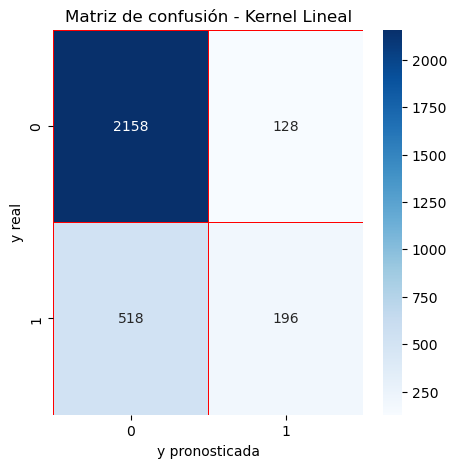

In [187]:
f, ax = plt.subplots(figsize=(5,5))

sns.heatmap(cm,annot=True,linewidths=0.5,linecolor="red",fmt=".0f",cmap="Blues",ax=ax)
plt.xlabel("y pronosticada")
plt.ylabel("y real")
plt.title("Matriz de confusión - Kernel Lineal")
plt.show()

In [49]:
# Estadísticas de desempeño
print(classification_report(y_test, yhat))

              precision    recall  f1-score   support

           0       0.81      0.94      0.87      2286
           1       0.60      0.27      0.38       714

    accuracy                           0.78      3000
   macro avg       0.71      0.61      0.62      3000
weighted avg       0.76      0.78      0.75      3000



In [188]:
# Guardar resultados del Kernel Lineal
modelo_lineal = clf
yhat_lineal = yhat

resultados.append({ "Kernel": "Lineal","Accuracy": accuracy_score(y_test, yhat),"F1 Abandona": f1_score(y_test, yhat)})

### Kernel Polinomial

In [189]:
clf = svm.SVC(kernel="poly")
clf.fit(X_train, y_train)

yhat = clf.predict(X_test)
yhat[0:5]

cm = confusion_matrix(y_test, yhat)
cm

array([[2220,   66],
       [ 101,  613]])

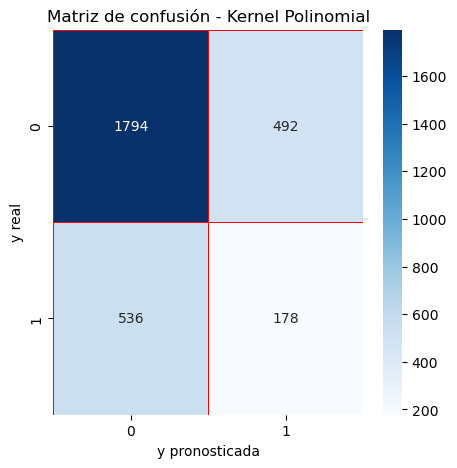

In [83]:
f, ax = plt.subplots(figsize=(5,5))

sns.heatmap(cm,annot=True,linewidths=0.5,linecolor="red",fmt=".0f",cmap="Blues", ax=ax)
plt.xlabel("y pronosticada")
plt.ylabel("y real")
plt.title("Matriz de confusión - Kernel Polinomial")
plt.show()

In [57]:
print(classification_report(y_test, yhat))

              precision    recall  f1-score   support

           0       0.96      0.97      0.96      2286
           1       0.90      0.86      0.88       714

    accuracy                           0.94      3000
   macro avg       0.93      0.91      0.92      3000
weighted avg       0.94      0.94      0.94      3000



In [85]:
# Guardar resultados del Kernel Polinomial
modelo_polinomial = clf
yhat_polinomial = yhat

resultados.append({"Kernel": "Polinomial","Accuracy": accuracy_score(y_test, yhat), "F1 Abandona": f1_score(y_test, yhat)})

### Kernel Sigmoide

In [60]:
clf = svm.SVC(kernel="sigmoid")
clf.fit(X_train, y_train)

yhat = clf.predict(X_test)
yhat[0:5]

cm = confusion_matrix(y_test, yhat)
cm

array([[1794,  492],
       [ 536,  178]])

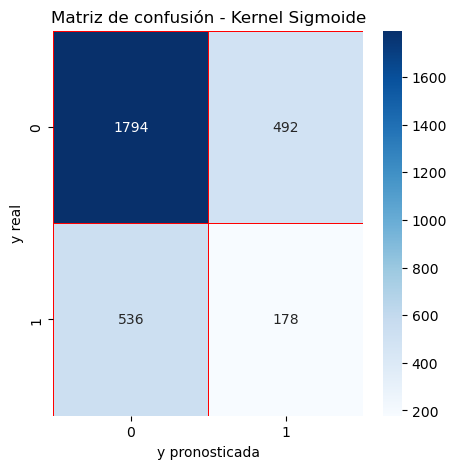

In [61]:
# Visualización de la matriz de confusión
f, ax = plt.subplots(figsize=(5,5))

sns.heatmap(cm,annot=True,linewidths=0.5,linecolor="red",fmt=".0f",cmap="Blues",ax=ax)
plt.xlabel("y pronosticada")
plt.ylabel("y real")
plt.title("Matriz de confusión - Kernel Sigmoide")
plt.show()

In [62]:
print(classification_report(y_test, yhat))

              precision    recall  f1-score   support

           0       0.77      0.78      0.78      2286
           1       0.27      0.25      0.26       714

    accuracy                           0.66      3000
   macro avg       0.52      0.52      0.52      3000
weighted avg       0.65      0.66      0.65      3000



In [87]:
# Guardar resultados del Kernel Sigmoide
modelo_sigmoide = clf
yhat_sigmoide = yhat

resultados.append({"Kernel": "Sigmoide","Accuracy": accuracy_score(y_test, yhat),"F1 Abandona": f1_score(y_test, yhat)})

### Tabla comparativa

In [67]:
comparacion = pd.DataFrame(resultados)
comparacion = comparacion.sort_values(by="F1 Abandona",ascending=False)
comparacion

,Kernel,Accuracy,F1 Abandona
0,RBF,0.953667,0.903271
2,Polinomial,0.944333,0.880115
3,Polinomial,0.944333,0.880115
1,Lineal,0.784667,0.377649
4,Sigmoide,0.657333,0.257225


In [68]:
mejor_kernel = comparacion.iloc[0]["Kernel"]
print("El modelo más adecuado es:", mejor_kernel)

El modelo más adecuado es: RBF


In [190]:
# Datos del empleado
empleado = pd.DataFrame({
    "satisfaction_level": [0.5],
    "last_evaluation": [0.75],
    "number_project": [4],
    "average_montly_hours": [200],
    "time_spend_company": [4],
    "Work_accident": [0],
    "promotion_last_5years": [0],
    "sales": ["sales"],
    "salary": ["medium"]
})

empleado

,satisfaction_level,last_evaluation,number_project,average_montly_hours,time_spend_company,Work_accident,promotion_last_5years,sales,salary
0,0.5,0.75,4,200,4,0,0,sales,medium


In [195]:
# Conversión de las variables categóricas
datos_empleado = pd.get_dummies(empleado, columns=["sales", "salary"], dtype=int)
# Igualar las columnas con las utilizadas en el entrenamiento
datos_empleado = datos_empleado.reindex(columns=feature_df.columns, fill_value=0)
# Estandarización del empleado
empleado_escalado = escalador.transform(datos_empleado)
datos_empleado

,satisfaction_level,last_evaluation,number_project,average_montly_hours,time_spend_company,Work_accident,promotion_last_5years,sales_IT,sales_RandD,sales_accounting,sales_hr,sales_management,sales_marketing,sales_product_mng,sales_sales,sales_support,sales_technical,salary_high,salary_low,salary_medium
0,0.5,0.75,4,200,4,0,0,0,0,0,0,0,0,0,1,0,0,0,0,1


In [193]:
# Predicción del empleado con el mejor modelo SVM
pronostico = mejor_modelo.predict(empleado_escalado)
empleado["Pronóstico"] = pronostico
empleado["Resultado"] = empleado["Pronóstico"].map({
    0: "Permanece en la empresa",
    1: "Abandona la empresa"})

empleado[["salary", "Pronóstico", "Resultado"]]

,salary,Pronóstico,Resultado
0,medium,0,Permanece en la empresa


In [197]:
# Predicción del empleado con el mejor modelo SVM
pronostico = mejor_modelo.predict(empleado_escalado)
empleado["Pronóstico"] = pronostico
empleado["Resultado"] = empleado["Pronóstico"].map({
    0: "Permanece en la empresa",
    1: "Abandona la empresa"
})

# Mostrar todas las variables y el resultado
pd.set_option("display.max_columns", None)

display(empleado)

,satisfaction_level,last_evaluation,number_project,average_montly_hours,time_spend_company,Work_accident,promotion_last_5years,sales,salary,Pronóstico,Resultado
0,0.5,0.75,4,200,4,0,0,sales,medium,0,Permanece en la empresa
